# 04 Delay drivers: grouped permutation importance (M5)

**Owner:** Mahmoud · **Due:** CP3 (Wed 4 Nov) · **Covers:** proposal (grouped permutation importance), research
question part 2 (*which order-time conditions drive long deliveries?*)

> **Draft.** Built on the features before the CP2 freeze. After the freeze and M4 tuning I *Run All* again;
> it uses the frozen HGB settings in `experiments/final_params/hgb.json`, the same model as `experiments.final`.

## Method

For each of the 4 CV folds I fit HGB on the earlier days, then shuffle one group of columns on the next day and see
how much the MAE goes up. A big jump means the model leans on that group. Columns in a group are shuffled together
(same row order), so features that only make sense together, like `tod_sin` and `tod_cos`, stay consistent.

The five groups come from Sumaiya's overlap check (02_eda §11). Time explains 55% of `load_15m_rel`, so shuffling
only one of them lets the other cover for it. That's why I also shuffle **time + load together**.

Each group is shuffled 5 times per fold, so the spread covers both the fold and the shuffle.

In [1]:
import json, os, sys
from pathlib import Path

# run from notebooks/ or the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import split
from common.config import RESULTS, SEED
from common.data import load_table
from common.features import FEATURE_SETS
from models import MODELS

FIG = ROOT / "figures" / "results"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    """Every report figure goes out as PDF + 300-dpi PNG, like figures/eda."""
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")

fs = FEATURE_SETS["base"]
train, _ = split.train_test(load_table())   # training days only; the test days are never touched here
print(f"training rows: {len(train):,}")

training rows: 406,553


In [2]:
GROUPS = {
    "distance": ["dist_haversine_km"],
    "prep": ["prep_min", "prep_missing", "prep_default"],
    "time of day": ["tod_sin", "tod_cos", "lunch_peak", "dinner_peak"],
    "load": ["load_15m_rel", "load_missing"],
    "district": ["district"],
}
GROUPS = {g: [c for c in cols if c in fs.columns] for g, cols in GROUPS.items()}
missing = set(fs.columns) - {c for cols in GROUPS.values() for c in cols}
assert not missing, f"features not in any group: {missing}"  # catches a renamed feature after the freeze
EXTRA = {"time of day + load": GROUPS["time of day"] + GROUPS["load"]}
REPEATS = 5

frozen = ROOT / "experiments" / "final_params" / "hgb.json"   # the frozen M4 settings, same as experiments.final
params = json.loads(frozen.read_text())["params"] if frozen.exists() else {}
print("HGB settings:", params or "defaults (no frozen params yet)")

HGB settings: {'loss': 'absolute_error', 'learning_rate': 0.03756560040604225, 'max_leaf_nodes': 76, 'min_samples_leaf': 70, 'l2_regularization': 7.852755494724242, 'max_iter': 800}


In [3]:
rng = np.random.default_rng(SEED)
rows, base_mae = [], {}
for fold, fit_rows, val_rows in split.forward_folds(train):
    est = MODELS["hgb"].make(fs, SEED, **params)
    est.fit(fit_rows[fs.columns], fit_rows["delivery_min"])
    X, y = val_rows[fs.columns].reset_index(drop=True), val_rows["delivery_min"].to_numpy()
    base = np.abs(y - est.predict(X)).mean()
    base_mae[fold] = base
    for group, cols in {**GROUPS, **EXTRA}.items():
        for r in range(REPEATS):
            Xp = X.copy()
            Xp[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            rows.append({"group": group, "fold": fold, "repeat": r,
                         "increase": np.abs(y - est.predict(Xp)).mean() - base})
    print(f"fold {fold}: {len(fit_rows):,} fit rows, {len(val_rows):,} scored, MAE {base:.3f}")
perm = pd.DataFrame(rows)

C:\Users\lynny\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\lynny\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\lynny\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\lynny\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

fold 1: 130,591 fit rows, 65,863 scored, MAE 6.098
fold 2: 196,454 fit rows, 65,981 scored, MAE 5.994
fold 3: 262,435 fit rows, 69,270 scored, MAE 6.437
fold 4: 331,705 fit rows, 74,848 scored, MAE 6.440


In [4]:
summary = (perm.groupby("group").increase.agg(["mean", "std", "min", "max"])
           .assign(pct_of_mae=lambda d: 100 * d["mean"] / np.mean(list(base_mae.values())))
           .sort_values("mean", ascending=False))
summary["rank"] = range(1, len(summary) + 1)
summary.round(3)

,mean,std,min,max,pct_of_mae,rank
group,,,,,,
distance,3.100,0.036,3.037,3.149,49.658,1
time of day + load,1.442,0.097,1.271,1.511,23.096,2
time of day,0.852,0.130,0.645,1.021,13.643,3
district,0.837,0.009,0.817,0.858,13.409,4
prep,0.677,0.018,0.649,0.704,10.847,5
load,0.198,0.050,0.119,0.254,3.167,6


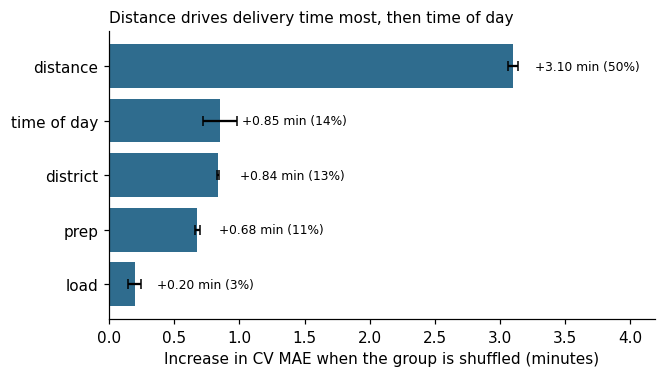

error bars: SD over 4 folds x 5 shuffles


In [5]:
main = summary.drop(index=list(EXTRA)).sort_values("mean")
top, second = main.index[-1], main.index[-2]

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.barh(main.index, main["mean"], xerr=main["std"], color=plt.cm.viridis(0.35), capsize=3)
for i, (m, p) in enumerate(zip(main["mean"], main["pct_of_mae"])):
    ax.text(m + main["std"].max() * 1.3, i, f"+{m:.2f} min ({p:.0f}%)", va="center", fontsize=8)
ax.set_xlabel("Increase in CV MAE when the group is shuffled (minutes)")
ax.set_xlim(0, main["mean"].max() * 1.35)
ax.set_title(f"{top.capitalize()} drives delivery time most, then {second}", fontsize=10, loc="left")
save(fig, "delay_drivers")
plt.show()
print("error bars: SD over 4 folds x", REPEATS, "shuffles")

## Did the proposal's expectation hold?

The proposal expected **distance, meal peaks and load** to be the top drivers.

In [6]:
order = list(summary.drop(index=list(EXTRA)).index)
for g in ["distance", "time of day", "load"]:
    print(f"{g:12s} rank {order.index(g) + 1} of {len(order)}, +{summary.loc[g, 'mean']:.2f} min")
joint = summary.loc["time of day + load", "mean"]
alone = summary.loc["time of day", "mean"] + summary.loc["load", "mean"]
print(f"time + load shuffled together: +{joint:.2f} min, vs +{alone:.2f} for the two shuffled one at a time")

distance     rank 1 of 5, +3.10 min
time of day  rank 2 of 5, +0.85 min
load         rank 5 of 5, +0.20 min
time + load shuffled together: +1.44 min, vs +1.05 for the two shuffled one at a time


**Reading:** distance is by far the top driver: shuffling it adds **3.10 min** to the CV MAE of 6.24 (50%).
Time of day (+0.85) and district (+0.84) come next, and their error bars overlap, so I can't rank one above the
other. Then prep (+0.68), and load is last (+0.20, 3%). So the proposal was right about distance and meal peaks,
but not about load. Shuffling time and load together adds 1.44 min, more than the 1.05 from shuffling them one
at a time. They overlap, so each one alone hides part of the other, as Sumaiya's §11 predicted.

**Informs:** the drivers slide (M9) and the Results section (M8). For the ops team: where and when to add couriers.

**Caveat for the report:** permutation importance shows what *the model* relies on, not what *causes* long
deliveries (Lec 4: a relationship, not a cause).